In [48]:
import glob
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

rc = {
    "axes.axisbelow": True,
    "axes.linewidth": 1.0,
    "axes.labelsize": "x-small",
    "axes.titlesize": "x-small",
    "figure.dpi": 150,
    "figure.figsize": (3.2, 3.2),
    "font.size": 12.0,
    "legend.fontsize": "xx-small",
    "lines.linewidth": 1.0,
    "savefig.transparent": True,
    "xtick.labelsize": "xx-small",
    "xtick.major.width": 1.0,
    "ytick.labelsize": "xx-small",
    "ytick.major.width": 1.0,
    "font.family": ["serif"],
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsfonts}",
}

plt.rcParams.update(rc)

BASE_PATH = '/Users/gabrieleaccarino/Workspace/waveletflux/experiments/'
PDE = 'turbulent_radiative_layer_2D'

In [154]:
models = {
    'WFM 1-scale seed42' : f"{BASE_PATH}/{PDE}/metrics/WaveletFlow_1scale_haar_v4.0_nsampling50_nens8_seed42_turbulent_radiative_layer_2D_metrics.csv",
    'WFM 1-scale seed84' : f"{BASE_PATH}/{PDE}/metrics/WaveletFlow_1scale_haar_v4.0_nsampling50_nens8_seed84_turbulent_radiative_layer_2D_metrics.csv",
    'WFM 1-scale seed168' : f"{BASE_PATH}/{PDE}/metrics/WaveletFlow_1scale_haar_v4.0_nsampling50_nens8_seed168_turbulent_radiative_layer_2D_metrics.csv",

    'WFM 3-scale seed42' : f"{BASE_PATH}/{PDE}/metrics/WaveletFlow_3scales_haar_v4.0_nsampling50_nens8_seed42_turbulent_radiative_layer_2D_metrics.csv",
    'WFM 3-scale seed84' : f"{BASE_PATH}/{PDE}/metrics/WaveletFlow_3scales_haar_v4.0_nsampling50_nens8_seed84_turbulent_radiative_layer_2D_metrics.csv",
    'WFM 3-scale seed168' : f"{BASE_PATH}/{PDE}/metrics/WaveletFlow_3scales_haar_v4.0_nsampling50_nens8_seed168_turbulent_radiative_layer_2D_metrics.csv",

    'FM_pixel seed42' : f"{BASE_PATH}/{PDE}/metrics/FM_data_space_v4.0_nsampling50_nens8_seed42_turbulent_radiative_layer_2D_metrics.csv",
    'FM_pixel seed84' : f"{BASE_PATH}/{PDE}/metrics/FM_data_space_v4.0_nsampling50_nens8_seed84_turbulent_radiative_layer_2D_metrics.csv",
    'FM_pixel seed168' : f"{BASE_PATH}/{PDE}/metrics/FM_data_space_v4.0_nsampling50_nens8_seed168_turbulent_radiative_layer_2D_metrics.csv",

    #'FM_fourier_32modes': f"{BASE_PATH}/{PDE}/metrics/FourierFlow_32modes_v4.0_nsampling50_nens8_seed42_turbulent_radiative_layer_2D_metrics.csv",
    'FM_fourier_16modes seed42': f"{BASE_PATH}/{PDE}/metrics/FourierFlow_16modes_v4.0_nsampling50_nens8_seed42_turbulent_radiative_layer_2D_metrics.csv",
    'FM_fourier_16modes seed84': f"{BASE_PATH}/{PDE}/metrics/FourierFlow_16modes_v4.0_nsampling50_nens8_seed84_turbulent_radiative_layer_2D_metrics.csv",
    'FM_fourier_16modes seed168': f"{BASE_PATH}/{PDE}/metrics/FourierFlow_16modes_v4.0_nsampling50_nens8_seed168_turbulent_radiative_layer_2D_metrics.csv"
}

In [155]:
dfs = []
for name, f in models.items():
    d = pd.read_csv(f)
    d["source"] = name          # full stem as a fallback identifier
    dfs.append(d)
df = pd.concat(dfs, ignore_index=True)  # columns aligned by name, NaN where absent

df["method"] = df["source"].str.replace(r"\s*seed\d+$", "", regex=True)

g  = df[df.field == "_global_"]
pf = df[df.field != "_global_"]

In [156]:
df

,model,traj,field,step,seed,dataset,n_ensemble,num_sampling_steps,ode_method,clamp_sigma,...,rmse_p_mid,rmse_p_vhigh,spread,spread_skill,std_err_corr,total_error,vrmse,w1,source,method
0,WaveletFlow_turbulent_radiative_layer_2D_1scal...,0,density,0,42,turbulent_radiative_layer_2D,8,50,euler,5.0,...,0.018416,326.744080,2.138377,1.093269,0.729228,0.002948,0.042601,0.709200,WFM 1-scale seed42,WFM 1-scale
1,WaveletFlow_turbulent_radiative_layer_2D_1scal...,0,density,1,42,turbulent_radiative_layer_2D,8,50,euler,5.0,...,0.016712,179.695175,2.658245,0.966332,0.736849,0.000277,0.060198,0.890838,WFM 1-scale seed42,WFM 1-scale
2,WaveletFlow_turbulent_radiative_layer_2D_1scal...,0,density,2,42,turbulent_radiative_layer_2D,8,50,euler,5.0,...,0.031576,814.114441,3.211290,0.863343,0.746569,0.002537,0.081810,1.007657,WFM 1-scale seed42,WFM 1-scale
3,WaveletFlow_turbulent_radiative_layer_2D_1scal...,0,density,3,42,turbulent_radiative_layer_2D,8,50,euler,5.0,...,0.046614,242.715561,3.788929,0.830888,0.769844,-0.000486,0.100801,1.139915,WFM 1-scale seed42,WFM 1-scale
4,WaveletFlow_turbulent_radiative_layer_2D_1scal...,0,density,4,42,turbulent_radiative_layer_2D,8,50,euler,5.0,...,0.040386,286.721985,4.048400,0.769739,0.745526,-0.002160,0.116799,1.124231,WFM 1-scale seed42,WFM 1-scale
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52375,FourierFlow_turbulent_radiative_layer_2D_16mod...,8,_global_,92,168,turbulent_radiative_layer_2D,8,50,euler,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FM_fourier_16modes seed168,FM_fourier_16modes
52376,FourierFlow_turbulent_radiative_layer_2D_16mod...,8,_global_,93,168,turbulent_radiative_layer_2D,8,50,euler,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FM_fourier_16modes seed168,FM_fourier_16modes
52377,FourierFlow_turbulent_radiative_layer_2D_16mod...,8,_global_,94,168,turbulent_radiative_layer_2D,8,50,euler,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FM_fourier_16modes seed168,FM_fourier_16modes
52378,FourierFlow_turbulent_radiative_layer_2D_16mod...,8,_global_,95,168,turbulent_radiative_layer_2D,8,50,euler,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FM_fourier_16modes seed168,FM_fourier_16modes


# Kinetic Energy

In [157]:
# one value per (method, seed, step): mean over trajectories
seed_curves = (g.groupby(["method", "seed", "step"], as_index=False)["ke_mae"].mean())

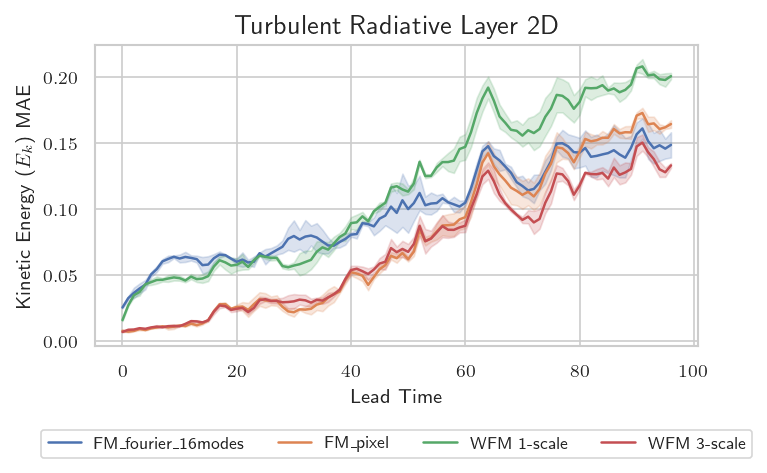

In [158]:
sns.set_theme(style="whitegrid", context="paper")

fig, ax = plt.subplots(figsize=(5.2, 3.4))
#sns.lineplot(data=g, x="step", y="ke_mae", hue="method", errorbar="se", ax=ax)
sns.lineplot(data=seed_curves, x="step", y="ke_mae", hue="method", errorbar="sd", ax=ax)   # band = spread across seeds
#sns.lineplot(data=seed_curves, x="step", y="ke_mae", hue="method", units="seed", estimator=None, alpha=0.6, ax=ax)  # one line per (method, seed)
ax.set_xlabel("Lead Time")
ax.set_ylabel(r"Kinetic Energy ($E_k$) MAE")   # was mislabeled "Bias"
ax.set_title("Turbulent Radiative Layer 2D", fontsize=13)
sns.move_legend(ax, title=None, ncol=4, fontsize=8, frameon=True, bbox_to_anchor=(0.5, -0.25), loc="upper center")
fig.tight_layout()
plt.show()

# Enstrophy

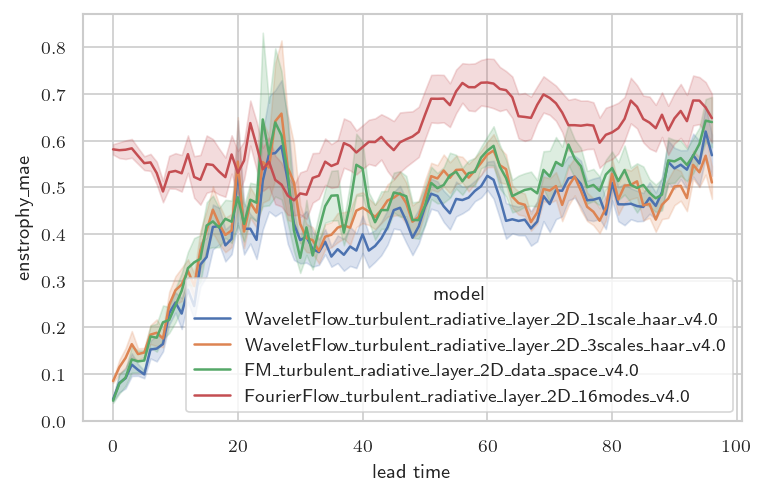

In [153]:
plt.figure(figsize=(5.2, 3.4))
sns.lineplot(data=g, x="step", y="enstrophy_mae", hue="model", errorbar="se")
#plt.yscale("log")
plt.xlabel("lead time")
plt.tight_layout()
plt.show()

# Gradient energy

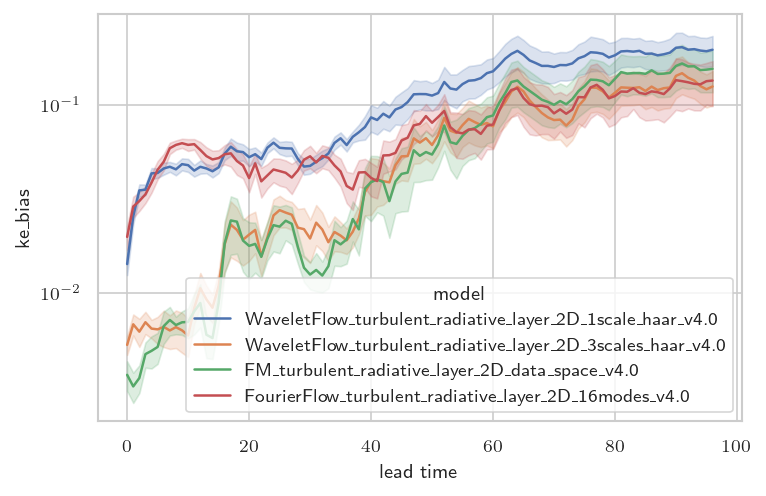

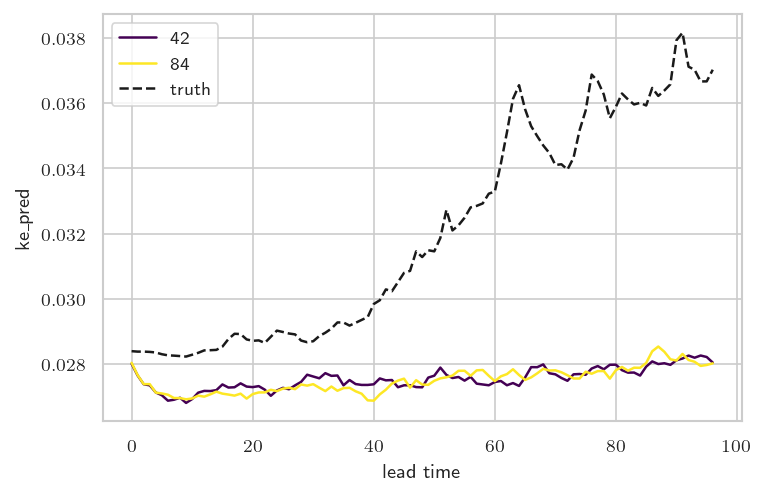

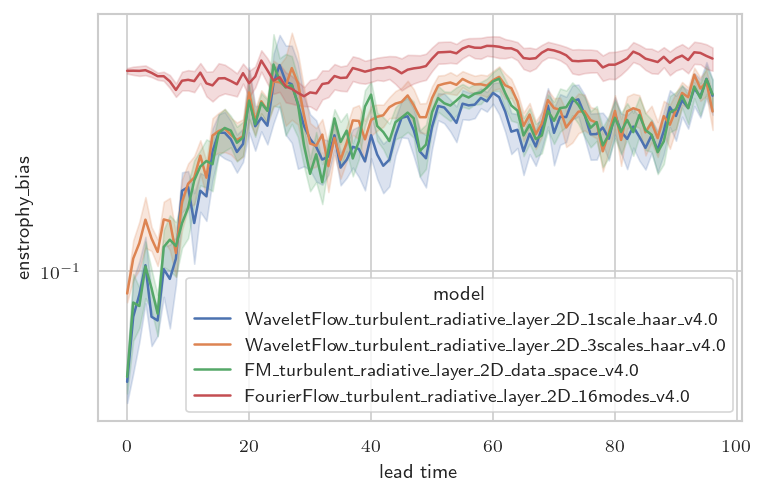

In [127]:
sns.set_theme(style="whitegrid", context="paper")

# ── Comparing MODELS (e.g. 1-scale vs 3-scale): hue="model" ─────────────────
plt.figure(figsize=(5.2, 3.4))
sns.lineplot(data=g, x="step", y="ke_bias", hue="model", errorbar="se")
plt.yscale("log"); plt.xlabel("lead time"); plt.tight_layout()

# ── Comparing SEEDS of the same model: one line per seed ────────────────────
one = g[g.model == g.model.unique()[0]]
plt.figure(figsize=(5.2, 3.4))
sns.lineplot(data=one, x="step", y="ke_pred",
             hue="seed", palette="viridis", estimator="mean", errorbar=None)
sns.lineplot(data=one, x="step", y="ke_true",
             color="k", ls="--", label="truth", errorbar=None)
plt.xlabel("lead time"); plt.tight_layout()

# ── Pooling seeds into ONE band per model (the UQ view) ─────────────────────
# errorbar="se" now measures spread across (traj × seed) jointly.
plt.figure(figsize=(5.2, 3.4))
sns.lineplot(data=g, x="step", y="enstrophy_bias", hue="model", errorbar="se")
plt.yscale("log"); plt.xlabel("lead time"); plt.tight_layout()
plt.show()

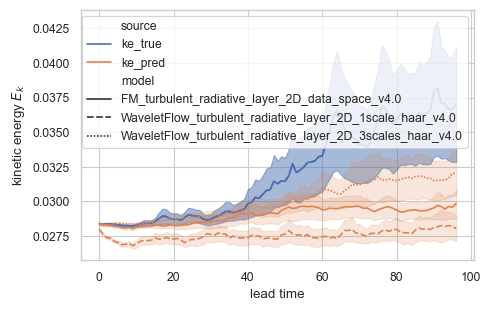

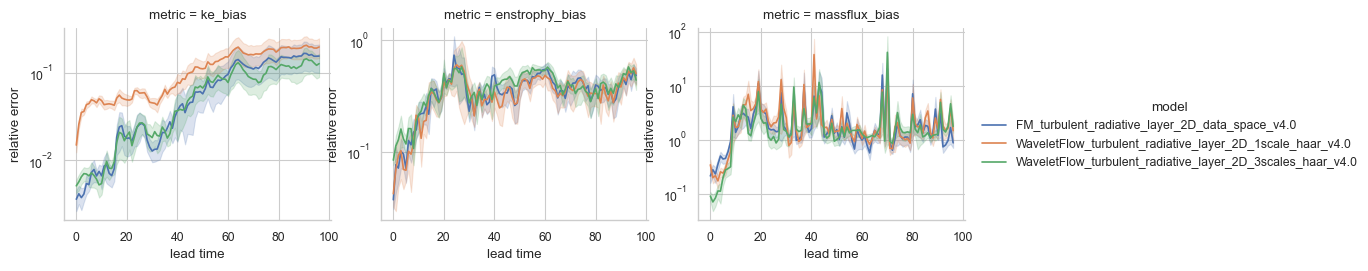

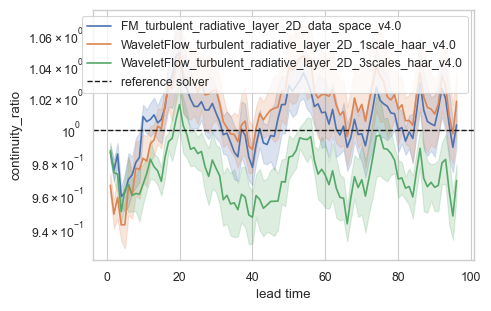

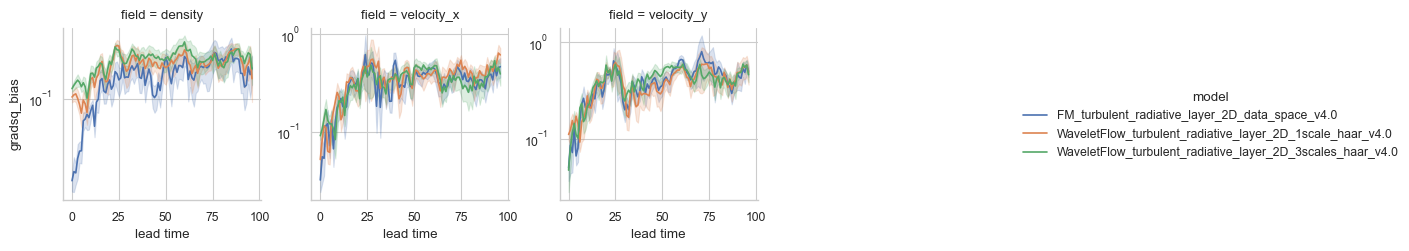

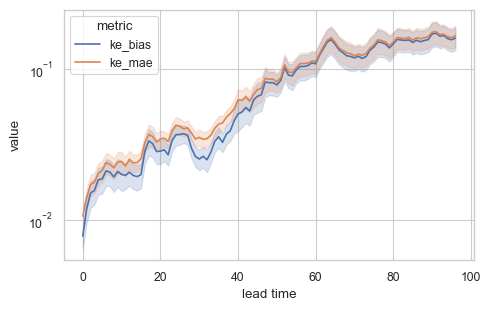

In [37]:
sns.set_theme(style="whitegrid", context="paper")

# ── 1. Kinetic energy: predicted vs true over the rollout ────────────────────
# ke_pred is already the per-member-then-averaged value; seaborn's band here
# is variability ACROSS TRAJECTORIES (and seeds, if you concat several CSVs).
m = g.melt(id_vars=["model", "traj", "step", "seed"],
           value_vars=["ke_true", "ke_pred"],
           var_name="source", value_name="ke")
plt.figure(figsize=(5, 3.2))
sns.lineplot(data=m, x="step", y="ke", hue="source",
             style="model", errorbar="se")
plt.ylabel("kinetic energy $E_k$"); plt.xlabel("lead time")
plt.tight_layout()

# ── 2. All global biases on one grid: is the model shedding energy? ──────────
bias_cols = ["ke_bias", "enstrophy_bias", "massflux_bias"]
mb = g.melt(id_vars=["model", "traj", "step", "seed"],
            value_vars=bias_cols, var_name="metric", value_name="rel_error")
fg = sns.relplot(data=mb, x="step", y="rel_error", col="metric",
                 hue="model", kind="line", errorbar="se",
                 col_wrap=3, height=2.8, aspect=1.2,
                 facet_kws=dict(sharey=False))
fg.set(yscale="log", xlabel="lead time", ylabel="relative error")

# ── 3. Conservation: continuity ratio, reference solver sits at 1.0 ──────────
plt.figure(figsize=(5, 3.2))
sns.lineplot(data=g, x="step", y="continuity_ratio",
             hue="model", errorbar="se")
plt.axhline(1.0, color="k", ls="--", lw=1, label="reference solver")
plt.yscale("log"); plt.xlabel("lead time"); plt.legend()
plt.tight_layout()

# ── 4. Per-field physics: gradient energy bias, one panel per field ──────────
fg = sns.relplot(data=pf.dropna(subset=["gradsq_bias"]),
                 x="step", y="gradsq_bias", col="field", hue="model",
                 kind="line", errorbar="se", col_wrap=4, height=2.6,
                 facet_kws=dict(sharey=False))
fg.set(yscale="log", xlabel="lead time")

# ── 5. Sanity crosscheck: bias vs mae separates "wrong attractor"
#      (both large) from "right attractor, different phase" (mae ≫ bias) ─────
mm = g.melt(id_vars=["model", "traj", "step"],
            value_vars=["ke_bias", "ke_mae"],
            var_name="metric", value_name="value")
plt.figure(figsize=(5, 3.2))
sns.lineplot(data=mm, x="step", y="value", hue="metric", errorbar="se")
plt.yscale("log"); plt.xlabel("lead time"); plt.tight_layout()
plt.show()